# 02. Resultados

Este notebook no entrena nada. Solo lee lo que generó el pipeline de DVC (`dvc repro`) en `reports/`, `models/` y `data/processed/`, para que los resultados siempre correspondan a la última versión de los datos y del código. Para correrlo primero hay que tener los datos con `dvc pull` o `dvc repro`. La justificación de cada algoritmo está en `docs/modelos.md`.

En cada modelo de clasificación se muestra la matriz de confusión con los alumnos de prueba y, debajo, cada métrica con la cuenta que la produce. VP son los que reprueban y el modelo detecta, FN los que reprueban y se le pasan, FP los que aprueban y marca en riesgo, y VN los que aprueban y deja bien.

In [1]:
import json
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import confusion_matrix

RAIZ = Path("..")
REPORTES = RAIZ / "reports"
pd.set_option("display.precision", 3)


def leer(nombre):
    return json.loads((REPORTES / "metrics" / nombre).read_text(encoding="utf-8"))


def titulo(texto):
    display(Markdown(f"**{texto}**"))


def pct(valor):
    return f"{valor:.1%}"


# alumnos de prueba, los mismos con los que el pipeline calculo las metricas
test = pd.read_csv(RAIZ / "data" / "processed" / "test.csv")
y_test = test["reprobado"]


def tablas_clasificacion(nombre_modelo, metricas):
    """matriz de confusion y tabla de metricas con la cuenta de cada una"""
    paquete = joblib.load(RAIZ / "models" / f"{nombre_modelo}.joblib")
    y_pred = paquete["modelo"].predict(test[paquete["columnas"]])
    vn, fp, fn, vp = (int(n) for n in confusion_matrix(y_test, y_pred).ravel())
    total = vn + fp + fn + vp

    matriz = pd.DataFrame([[vn, fp, vn + fp], [fn, vp, fn + vp], [vn + fn, fp + vp, total]],
                          index=["aprobó", "reprobó", "total"],
                          columns=["predice aprueba", "predice reprueba", "total"])
    matriz = matriz.rename_axis(index="real", columns="modelo")

    tabla = pd.DataFrame({
        "cuenta": [f"(VP + VN) / total = ({vp} + {vn}) / {total}",
                   f"VP / (VP + FP) = {vp} / {vp + fp}",
                   f"VP / (VP + FN) = {vp} / {vp + fn}",
                   "2 × precisión × recall / (precisión + recall)",
                   f"FP / (FP + VN) = {fp} / {fp + vn}"],
        "valor": [metricas["exactitud"], metricas["precision"], metricas["recall"], metricas["f1"],
                  round(fp / (fp + vn), 4)],
    }, index=["exactitud", "precisión", "recall", "F1", "falsas alarmas"])
    tabla["porcentaje"] = tabla["valor"].map(pct)
    tabla.loc["F1", "porcentaje"] = ""
    return matriz, tabla


def tabla_equidad(metricas):
    equidad = pd.DataFrame(metricas["equidad"]).T
    equidad.index = equidad.index.str.replace("_", " ")
    equidad["alumnos"] = equidad["alumnos"].astype(int)
    equidad["recall"] = equidad["recall"].map(pct)
    equidad["falsas alarmas"] = equidad.pop("falsas_alarmas").map(pct)
    return equidad.rename_axis("grupo")


limpieza = leer("limpieza.json")
faltas = limpieza["outliers"]["absences"]
titulo("Limpieza de los datos")
pd.DataFrame({"resultado": [
    limpieza["filas_originales"],
    limpieza["duplicados_quitados"],
    sum(limpieza["fuera_de_rango"].values()),
    len(limpieza["faltantes_antes"]),
    limpieza["g3_cero_quitados"],
    faltas["maximo_original"],
    faltas["limite_superior"],
    faltas["valores_recortados"],
    limpieza["filas_finales"],
]}, index=[
    "alumnos originales",
    "renglones duplicados quitados",
    "valores fuera de rango",
    "columnas con faltantes",
    "alumnos con G3 en 0 quitados",
    "máximo de faltas antes de recortar",
    "límite de faltas con IQR",
    "alumnos con faltas recortadas al límite",
    "alumnos finales",
]).astype(int).rename_axis("paso")

**Limpieza de los datos**

,resultado
paso,
alumnos originales,649
renglones duplicados quitados,0
valores fuera de rango,0
columnas con faltantes,0
alumnos con G3 en 0 quitados,15
máximo de faltas antes de recortar,32
límite de faltas con IQR,15
alumnos con faltas recortadas al límite,21
alumnos finales,634


## 1. Regresión logística

¿Qué factores se relacionan con reprobar, sin conocer ninguna calificación?

**Matriz de confusión con los 127 alumnos de prueba**

modelo,predice aprueba,predice reprueba,total
real,,,
aprobó,90,20,110
reprobó,7,10,17
total,97,30,127


**Métricas y cómo se calcula cada una**

,cuenta,valor,porcentaje
exactitud,(VP + VN) / total = (10 + 90) / 127,0.787,78.7%
precisión,VP / (VP + FP) = 10 / 30,0.333,33.3%
recall,VP / (VP + FN) = 10 / 17,0.588,58.8%
F1,2 × precisión × recall / (precisión + recall),0.425,
falsas alarmas,FP / (FP + VN) = 20 / 110,0.182,18.2%


**Log-loss, entre más bajo mejor**

,log-loss
entrenamiento,0.414
prueba,0.517


**Las 12 variables con más peso (datos escalados)**

,coeficiente,efecto
variable,,
school_ms,0.870,sube el riesgo
failures,0.866,sube el riesgo
absences,0.610,sube el riesgo
guardian_mother,0.539,sube el riesgo
Fjob_services,0.443,sube el riesgo
freetime,0.363,sube el riesgo
schoolsup,0.356,sube el riesgo
Fjob_other,0.314,sube el riesgo
age,-0.492,baja el riesgo


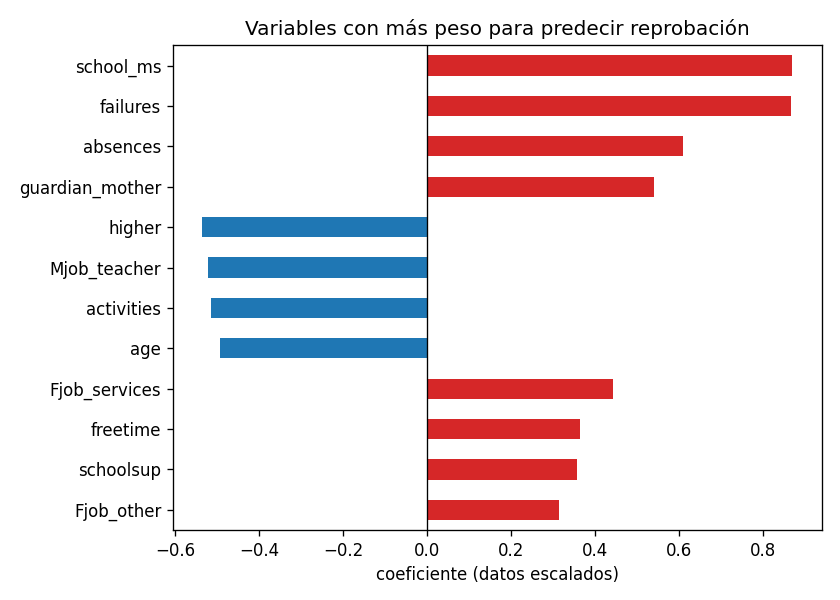

**Revisión de sesgo por grupo**

,alumnos,recall,falsas alarmas
grupo,,,
mujeres,77,57.1%,17.1%
hombres,50,60.0%,20.0%
zona rural,32,75.0%,33.3%
zona urbana,95,44.4%,14.0%


In [2]:
log = leer("logistica.json")
matriz_log, tabla_log = tablas_clasificacion("logistica", log)

titulo("Matriz de confusión con los 127 alumnos de prueba")
display(matriz_log)

titulo("Métricas y cómo se calcula cada una")
display(tabla_log)

titulo("Log-loss, entre más bajo mejor")
display(pd.DataFrame({"log-loss": [log["log_loss_train"], log["log_loss_test"]]},
                     index=["entrenamiento", "prueba"]))

titulo("Las 12 variables con más peso (datos escalados)")
coef = pd.Series(log["coeficientes_principales"]).sort_values(ascending=False)
display(pd.DataFrame({"coeficiente": coef,
                      "efecto": ["sube el riesgo" if v > 0 else "baja el riesgo" for v in coef]})
        .rename_axis("variable"))
display(Image(REPORTES / "figures" / "logistica_coeficientes.png"))

titulo("Revisión de sesgo por grupo")
tabla_equidad(log)

**Interpretación.** La regresión logística detecta 10 de los 17 alumnos que reprueban en los datos de prueba, o sea un recall de 59%. A cambio da bastantes falsas alarmas, porque de cada tres alumnos que marca como en riesgo solo uno reprueba de verdad (precisión de 33%). Para lo que queremos nos parece un buen balance, porque es peor dejar sin apoyo a alguien que lo necesita que ofrecerle ayuda a alguien que no la necesitaba. La exactitud de 79% parece baja si la comparamos con el 87% que sacaría un modelo que siempre dice "aprueba", pero ese modelo no detectaría a ningún alumno en riesgo.

Las variables que más suben el riesgo son estudiar en la escuela MS, haber reprobado materias antes y faltar mucho. Las que lo bajan son querer estudiar la universidad, hacer actividades extraescolares y que la mamá sea maestra. Hay que tener cuidado con algunos coeficientes. Por ejemplo, la edad sale negativa, como si ser más grande bajara el riesgo, y creemos que es porque la edad está muy relacionada con haber reprobado antes (los que repiten son más grandes) y el modelo reparte el efecto entre las dos variables.

Algo parecido nos pasó con el alcohol. Al principio usábamos el alcohol entre semana y el de fin de semana por separado, y al probar la app vimos que subir el alcohol entre semana bajaba la probabilidad de reprobar. Pasaba porque las dos variables van muy juntas y el modelo las usaba como contrapeso una de la otra. Por eso las juntamos en una sola variable con su promedio, y el modelo quedó igual de bueno pero ya sin ese resultado raro.

El log-loss sube de 0.41 en entrenamiento a 0.52 en prueba, así que el modelo se sobreajusta un poco, aunque no mucho.

En la tabla de equidad se ve que el modelo trata distinto a los alumnos de zona rural. Les da 33% de falsas alarmas contra 14% a los de zona urbana, o sea que marca como en riesgo a más alumnos rurales que en realidad aprueban. Entre hombres y mujeres la diferencia es más chica (20% contra 17%). Hay que tomarlo con calma porque en la prueba solo hay 32 alumnos rurales, pero es justo el tipo de sesgo que mencionamos en el análisis ético.

## 2. Árbol de decisión

¿Qué reglas sencillas podría usar una escuela para detectar alumnos en riesgo?

**Matriz de confusión con los 127 alumnos de prueba**

modelo,predice aprueba,predice reprueba,total
real,,,
aprobó,97,13,110
reprobó,8,9,17
total,105,22,127


**Métricas y cómo se calcula cada una**

,cuenta,valor,porcentaje
exactitud,(VP + VN) / total = (9 + 97) / 127,0.835,83.5%
precisión,VP / (VP + FP) = 9 / 22,0.409,40.9%
recall,VP / (VP + FN) = 9 / 17,0.529,52.9%
F1,2 × precisión × recall / (precisión + recall),0.462,
falsas alarmas,FP / (FP + VN) = 13 / 110,0.118,11.8%


**Exactitud en entrenamiento contra prueba, para revisar sobreajuste**

,exactitud
entrenamiento,0.862
prueba,0.835


**Importancia de las variables**

,importancia,porcentaje
variable,,
failures,0.519,51.9%
higher,0.246,24.6%
school_ms,0.132,13.2%
reason_home,0.074,7.4%
famsize_le3,0.018,1.8%
health,0.012,1.2%


**Reglas del árbol**

|--- failures <= 0.50
|   |--- higher <= 0.50
|   |   |--- health <= 3.50
|   |   |   |--- class: 1
|   |   |--- health >  3.50
|   |   |   |--- class: 1
|   |--- higher >  0.50
|   |   |--- school_ms <= 0.50
|   |   |   |--- class: 0
|   |   |--- school_ms >  0.50
|   |   |   |--- class: 0
|--- failures >  0.50
|   |--- reason_home <= 0.50
|   |   |--- famsize_le3 <= 0.50
|   |   |   |--- class: 1
|   |   |--- famsize_le3 >  0.50
|   |   |   |--- class: 1
|   |--- reason_home >  0.50
|   |   |--- class: 0



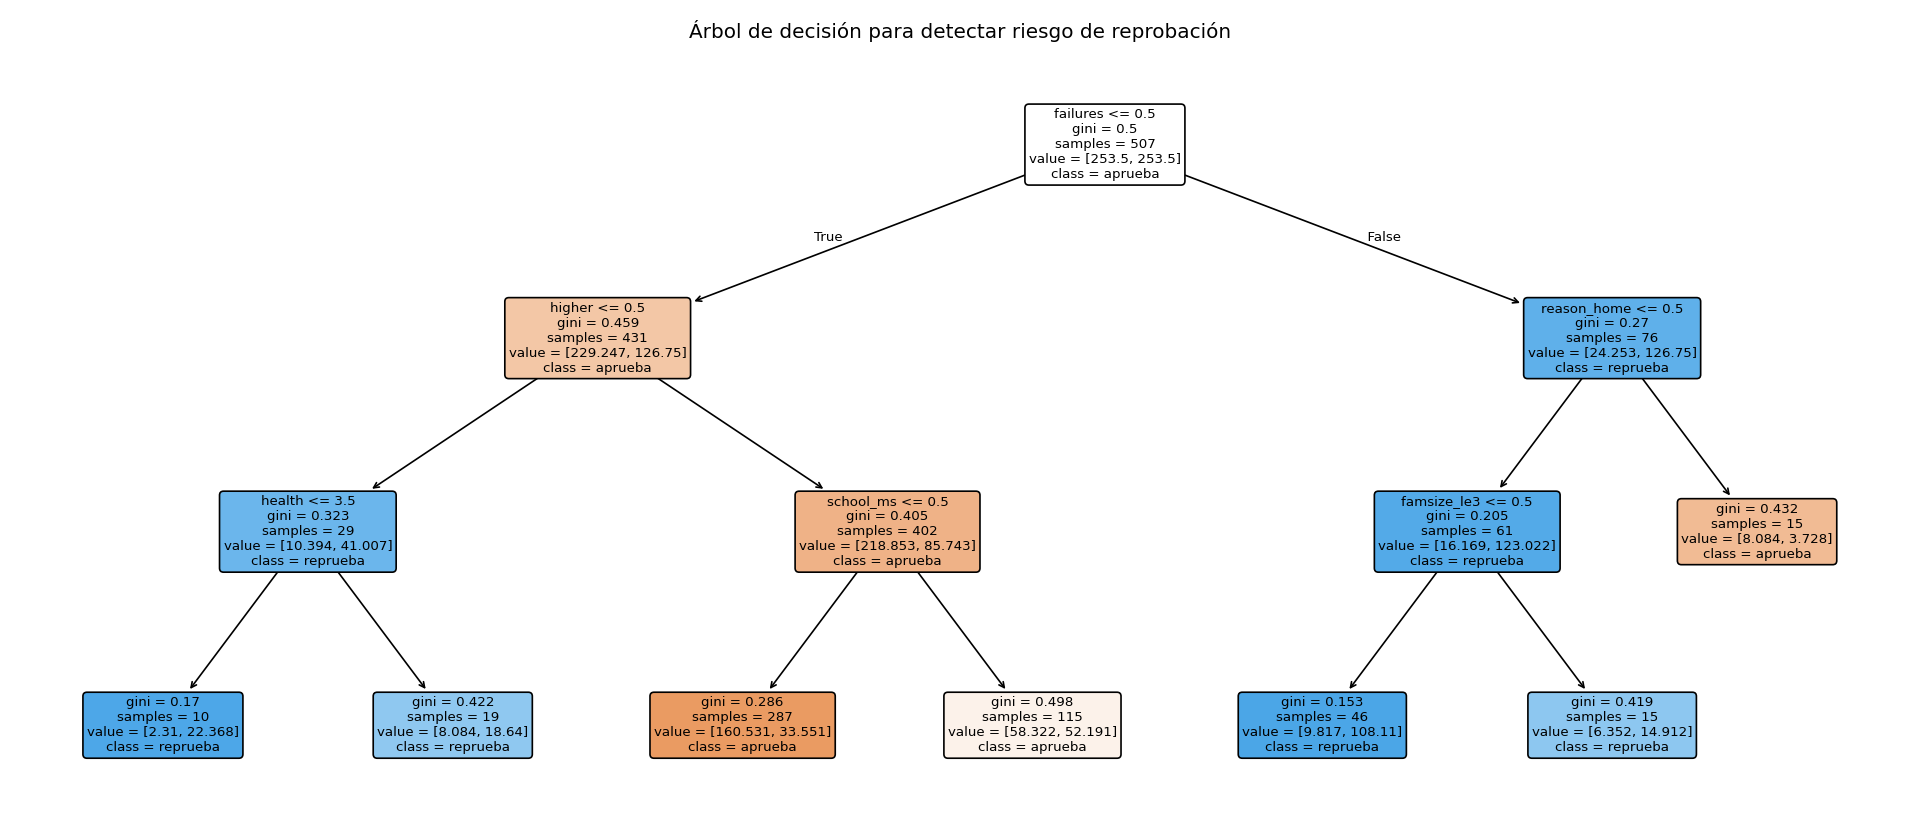

**Revisión de sesgo por grupo**

,alumnos,recall,falsas alarmas
grupo,,,
mujeres,77,57.1%,8.6%
hombres,50,50.0%,17.5%
zona rural,32,50.0%,25.0%
zona urbana,95,55.6%,8.1%


In [3]:
arbol = leer("arbol.json")
matriz_arbol, tabla_arbol = tablas_clasificacion("arbol", arbol)

titulo("Matriz de confusión con los 127 alumnos de prueba")
display(matriz_arbol)

titulo("Métricas y cómo se calcula cada una")
display(tabla_arbol)

titulo("Exactitud en entrenamiento contra prueba, para revisar sobreajuste")
display(pd.DataFrame({"exactitud": [arbol["exactitud_train"], arbol["exactitud"]]},
                     index=["entrenamiento", "prueba"]))

titulo("Importancia de las variables")
importancia = pd.Series(arbol["importancia_variables"])
display(pd.DataFrame({"importancia": importancia, "porcentaje": importancia.map(pct)}).rename_axis("variable"))

titulo("Reglas del árbol")
print((REPORTES / "metrics" / "arbol_reglas.txt").read_text(encoding="utf-8"))
display(Image(REPORTES / "figures" / "arbol.png"))

titulo("Revisión de sesgo por grupo")
tabla_equidad(arbol)

In [4]:
# comparacion de los dos modelos de clasificacion con los mismos alumnos de prueba
titulo("Regresión logística contra árbol de decisión")
pd.DataFrame({
    "regresión logística": tabla_log["valor"],
    "árbol de decisión": tabla_arbol["valor"],
}).T

**Regresión logística contra árbol de decisión**

,exactitud,precisión,recall,F1,falsas alarmas
regresión logística,0.787,0.333,0.588,0.425,0.182
árbol de decisión,0.835,0.409,0.529,0.462,0.118


**Interpretación.** El árbol llega a 83% de exactitud y detecta 9 de los 17 alumnos que reprueban (recall de 53%). En entrenamiento saca 86%, casi lo mismo que en prueba, así que no se está sobreajustando.

Sus reglas se pueden leer así. Si el alumno nunca ha reprobado y no quiere ir a la universidad, el árbol dice que hay riesgo. Si nunca ha reprobado y sí quiere ir, dice que aprueba. Si ya reprobó antes, casi siempre dice que hay riesgo, menos cuando eligió la escuela por estar cerca de su casa. Esa última regla nos parece rara y seguramente sale de pocos alumnos, así que no la tomaríamos muy en serio.

También notamos que algunas divisiones del árbol, como la de salud o la del tamaño de la familia, mandan a la misma clase de los dos lados. El árbol las hace porque separan un poco mejor a los grupos, pero no cambian la predicción, así que con profundidad 2 las reglas quedarían todavía más sencillas.

Comparado con la regresión logística, el árbol detecta un poco menos de reprobados (53% contra 59%), pero tiene menos falsas alarmas (precisión de 41% contra 33%) y también es menos injusto con los alumnos rurales (25% de falsas alarmas contra 33%). Los dos modelos coinciden en que lo que más importa es haber reprobado antes y querer estudiar la universidad. Si una escuela quisiera detectar a la mayor cantidad posible de alumnos en riesgo usaríamos la logística, y si quisiera reglas que se puedan explicar fácil a maestros y papás usaríamos el árbol.

## 3. K-means (no supervisado)

¿Qué perfiles de estudiantes hay según sus hábitos y en cuál se reprueba más?

**Inercia y silueta para cada K**

,inercia,silueta
K,,
2,2902.0,0.263
3,2540.8,0.164
4,2275.3,0.173
5,2039.4,0.182
6,1877.2,0.177
7,1749.4,0.177
8,1675.8,0.165
9,1581.7,0.175
10,1533.2,0.156


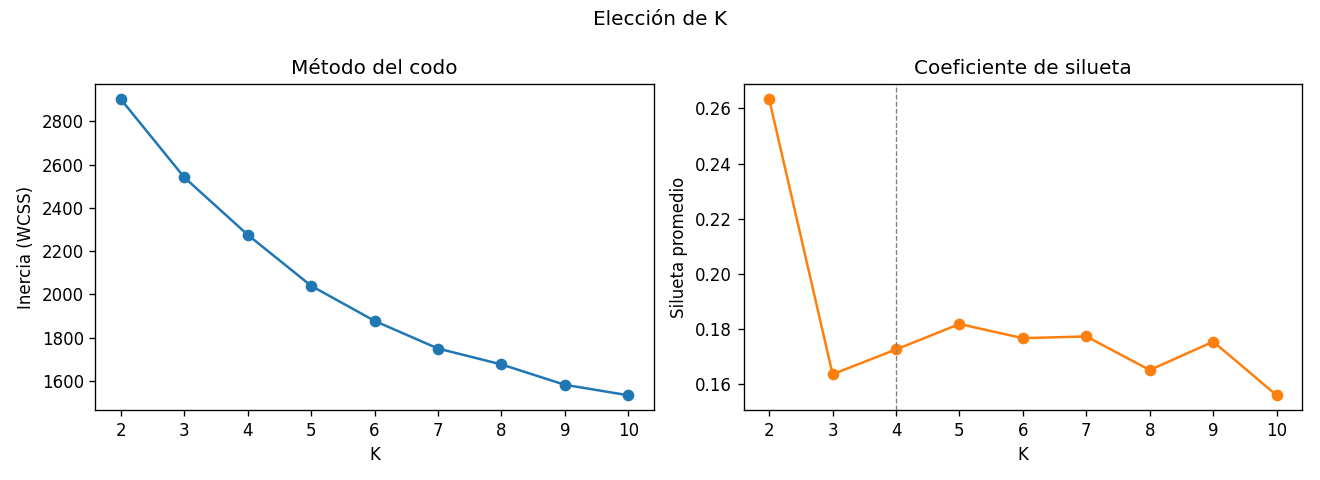

**Promedio de cada perfil con K = 4 (silueta 0.17)**

,nombre,estudio (1 a 4),tiempo libre (1 a 5),salidas (1 a 5),alcohol entre semana (1 a 5),alcohol fin de semana (1 a 5),faltas,alumnos,% que reprueba
perfil,,,,,,,,,
1,estudiosos,3.27,2.96,2.73,1.17,1.62,2.53,113,5.3
2,ocupados,1.58,2.30,2.28,1.15,1.91,4.22,172,12.2
0,sociables tranquilos,1.74,3.77,3.64,1.14,1.85,2.35,221,13.6
3,fiesteros,1.61,3.49,4.04,2.85,4.07,5.84,128,21.9


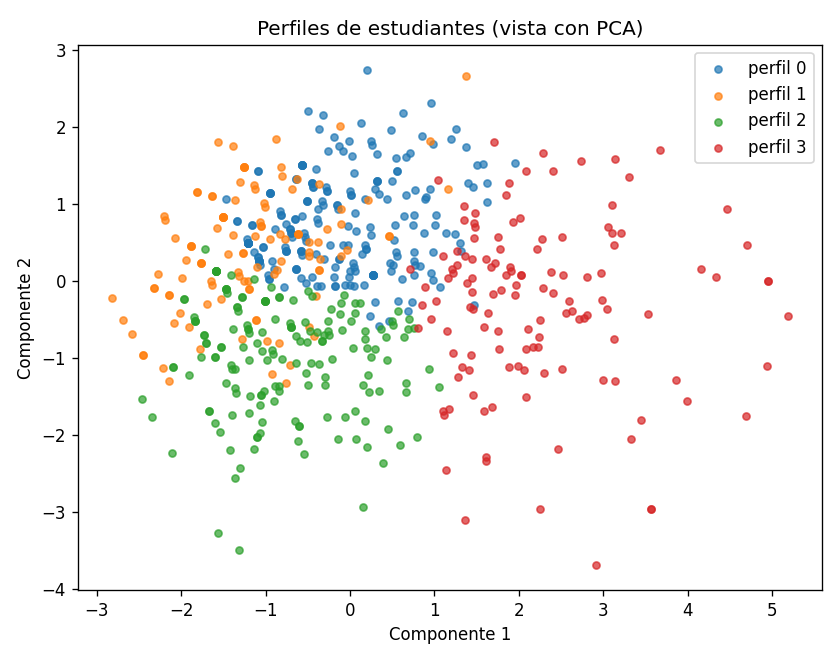

In [5]:
km = leer("kmeans.json")

titulo("Inercia y silueta para cada K")
display(pd.DataFrame({"inercia": km["inercia_por_k"], "silueta": km["silueta_por_k"]})
        .rename_axis("K"))
display(Image(REPORTES / "figures" / "kmeans_elegir_k.png"))

perfiles = pd.read_csv(REPORTES / "metrics" / "kmeans_perfiles.csv", index_col="perfil")


def nombrar(tabla):
    """mismo criterio que la app, por promedios y no por el numero del perfil"""
    restantes = list(tabla.index)
    nombres = {}
    for nombre, columna in [("estudiosos", "studytime"), ("fiesteros", "Walc"), ("sociables tranquilos", "goout")]:
        elegido = tabla.loc[restantes, columna].idxmax()
        nombres[elegido] = nombre
        restantes.remove(elegido)
    for p in restantes:
        nombres[p] = "ocupados"
    return nombres


perfiles.insert(0, "nombre", pd.Series(nombrar(perfiles)))
perfiles["alumnos"] = perfiles["alumnos"].astype(int)
perfiles = perfiles.rename(columns={
    "studytime": "estudio (1 a 4)",
    "freetime": "tiempo libre (1 a 5)",
    "goout": "salidas (1 a 5)",
    "Dalc": "alcohol entre semana (1 a 5)",
    "Walc": "alcohol fin de semana (1 a 5)",
    "absences": "faltas",
    "porcentaje_reprobados": "% que reprueba",
}).sort_values("% que reprueba")

titulo(f"Promedio de cada perfil con K = {km['k_elegido']} (silueta {km['silueta_k_elegido']:.2f})")
display(perfiles)
display(Image(REPORTES / "figures" / "kmeans_perfiles_pca.png"))

**Interpretación.** Con el método del codo no se ve un codo claro, la inercia va bajando casi parejo. La silueta más alta sale con K = 2 (0.26), pero esos dos grupos solo separan a los alumnos que salen mucho, toman más y faltan más del resto, y eso no nos dice mucho sobre los distintos tipos de estudiantes. Con K = 3 los alumnos que estudian más quedan revueltos con los que casi no salen. De K = 3 a K = 6 la silueta queda casi igual, entre 0.16 y 0.18, así que elegimos K = 4 porque es el K más chico donde aparece separado un grupo de alumnos estudiosos y los cuatro grupos se pueden describir fácil.

Estos son los nombres que les dimos.

**Perfil 0, sociables tranquilos (221 alumnos).** Estudian poco, tienen bastante tiempo libre y salen seguido, pero casi no toman y faltan poco. Reprueba el 13.6%, muy cerca del promedio.

**Perfil 1, estudiosos (113 alumnos).** Son los únicos que en promedio estudian más de 5 horas a la semana, y salen menos que los demás. Es el grupo que menos reprueba, solo el 5.3%.

**Perfil 2, ocupados (172 alumnos).** Estudian poco, pero también tienen poco tiempo libre y casi no salen. Faltan un poco más que los dos primeros. Reprueba el 12.2%.

**Perfil 3, fiesteros (128 alumnos).** Salen mucho, son los que más alcohol toman (sobre todo en fin de semana) y los que más faltan. Reprueba el 21.9%, cuatro veces más que los estudiosos.

La silueta de 0.17 es baja, o sea que los grupos se enciman bastante. Creemos que es porque los hábitos de los alumnos no forman grupos muy separados, más bien van cambiando poco a poco de un alumno a otro. Aun así, los perfiles sí muestran una diferencia clara en cuánto se reprueba, y hay que recordar que K-means nunca vio la columna de reprobado, así que esa relación salió sola.

## 4. Regresión lineal

¿Qué tanto se puede predecir la calificación final y cuánto ayuda conocer la del primer periodo?

**Regresión lineal de la calificación final, con los 127 alumnos de prueba**

,R²,MAE (puntos),RMSE (puntos)
modelo,,,
sin calificaciones,0.320,1.879,2.431
con la calificación del 1er periodo (G1),0.747,1.076,1.483


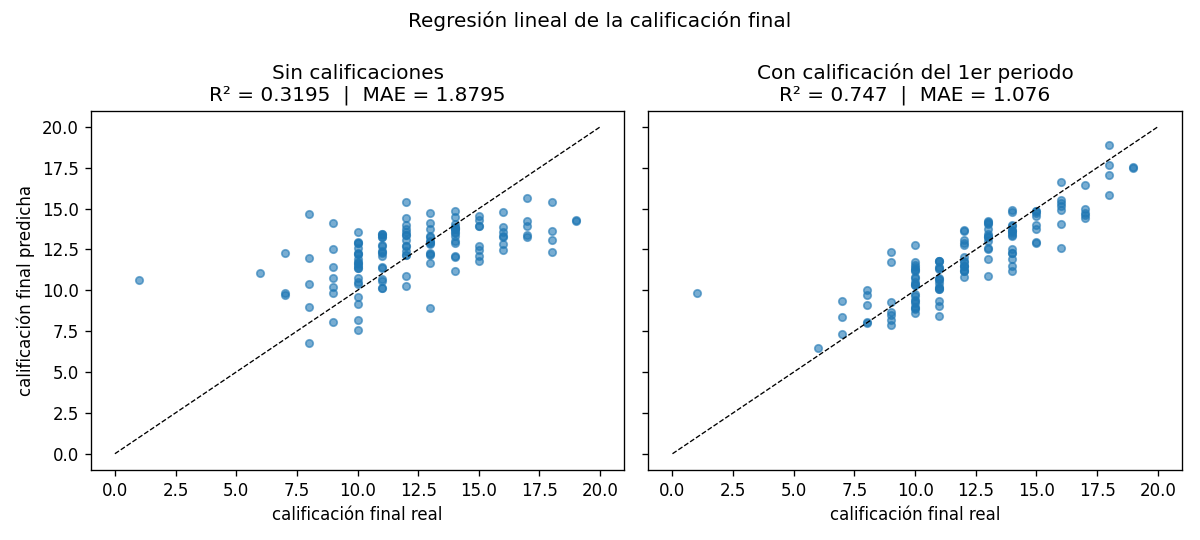

In [6]:
lineal = pd.DataFrame(leer("lineal.json")).T
lineal = lineal.rename(index={"sin_calificaciones": "sin calificaciones",
                              "con_primer_periodo": "con la calificación del 1er periodo (G1)"},
                       columns={"r2": "R²", "mae": "MAE (puntos)", "rmse": "RMSE (puntos)"})
titulo("Regresión lineal de la calificación final, con los 127 alumnos de prueba")
display(lineal.rename_axis("modelo"))
display(Image(REPORTES / "figures" / "lineal_real_vs_predicho.png"))

**Interpretación.** Sin ninguna calificación, la regresión lineal explica 32% de la variación de la calificación final y se equivoca en promedio por 1.9 puntos. Cuando le agregamos solo la calificación del primer periodo, el R² sube a 0.75 y el error baja a 1.1 puntos. En la gráfica se ve muy claro, los puntos del segundo modelo quedan mucho más pegados a la diagonal.

Esto quiere decir que una sola calificación dice más sobre cómo le va a ir a un alumno que todo su contexto junto (familia, hábitos y escuela). Para una escuela, la mejor señal de alerta es el primer periodo, y los modelos sin calificaciones sirven para poner atención antes de tener esa información, por ejemplo al inicio del año. Un error de 1.9 puntos en una escala de 20 tampoco es poco, porque puede ser la diferencia entre sacar 9 o 11, o sea entre reprobar y aprobar.

## Conclusiones

Lo que más nos llamó la atención es que los cuatro algoritmos apuntan más o menos a lo mismo. Haber reprobado antes y no querer estudiar la universidad es lo que más pesa en los dos modelos de clasificación, y en K-means el grupo que más reprueba es el que sale más, toma más y falta más. O sea que el riesgo de reprobar tiene que ver sobre todo con la historia del alumno en la escuela y con sus hábitos, más que con su familia.

También vimos que predecir quién va a reprobar sin conocer sus calificaciones es difícil. Los dos modelos de clasificación detectan poco más de la mitad de los alumnos que reprueban, y la regresión lineal solo explica 32% de la calificación final con el contexto. En cuanto se conoce la calificación del primer periodo todo mejora muchísimo, así que la mejor señal de alerta para una escuela sigue siendo el desempeño temprano, y estos modelos servirían más bien para poner atención antes de que exista esa primera calificación.

Con la limpieza aprendimos que no basta con revisar si hay datos faltantes. El dataset no tenía ninguno, pero sí tenía ceros en la calificación final que en realidad eran alumnos que no presentaron, y si no los hubiéramos quitado los modelos habrían aprendido algo que no es cierto. Algo parecido pasó con la exactitud, que parecía una buena métrica hasta que nos dimos cuenta de que un modelo que dice siempre "aprueba" saca 87%.

En la parte ética encontramos un sesgo real, porque la regresión logística da el doble de falsas alarmas a los alumnos de zona rural. Por eso creemos que un modelo así solo debería usarse para ofrecer apoyo y siempre con una persona revisando, nunca para tomar decisiones por su cuenta. Además, los datos son de dos escuelas de Portugal de hace casi 20 años, así que no se pueden aplicar directo a escuelas de México, y lo que encontramos son relaciones, no causas.

Trabajar con DVC nos ayudó a probar cambios sin perder el control. Cada vez que cambiábamos un parámetro, `dvc repro` volvía a correr solo lo necesario, con `dvc metrics diff` veíamos si el cambio mejoraba o empeoraba los resultados, y todo quedaba ligado a un commit, así que siempre sabíamos qué datos y qué código produjeron cada resultado.